# Bloque C - C7: Color sobre las células segmentadas por el pipeline

**Objetivo:** pasar de las células delimitadas con el **GT** (C4-C5) a las células que **segmenta el pipeline** (Bloque A: Otsu + Watershed + exclusión de glóbulos blancos), y comprobar si el criterio de color sigue funcionando. Corresponde a las tareas pendientes del grupo en las que participa el Bloque C:
1. Comprobar si las **características de color** siguen separando parasitadas y sanas en las células segmentadas.
2. Evaluar el **criterio de color** de C5 con **validación dejando un paciente afuera**.
3. Calcular la **parasitemia** (porcentaje de eritrocitos infectados) y la **máscara final** de eritrocitos infectados, y compararlas con el GT.

**Cómo, sin modificar nada fuera de `color_stain/`:**
- Para segmentar usamos la función del Bloque A (`segmentation.a1_segmentacion_base.procesar_imagen`) con los mismos ajustes que `main.py` (Otsu, Watershed y exclusión de glóbulos blancos con `detectar_wbc`). Esa función guarda los recortes en una carpeta: le pasamos una **carpeta temporal fuera del repositorio**, que se borra al final.
- Para saber la clase del GT de cada célula detectada usamos `main.evaluar_contra_gt`, la misma que usa `main.py` (correspondencia célula a célula con IoU ≥ 0.5).
- El color se calcula con `color_features.caracteristicas_celula` y la decisión con el nuevo `color_classifier.py`. **No se modifica ningún archivo de los otros bloques**: solo se importan sus funciones.

**Solo train.** Test no se usa.

In [1]:
# BLOQUE C - C7: Color sobre las células segmentadas por el pipeline (solo train)

import sys
sys.path.append("..")  # el notebook está en color_stain/, subimos un nivel para poder importar common/ y los otros bloques

import shutil
import tempfile
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from common.config import LABEL_PARASITIZED, LABEL_UNINFECTED, LABEL_WBC
from common.io_utils import cargar_subset, cargar_imagen, cargar_gt
from common.generar_gt_utils import mapa_gt
from segmentation.preprocess import mascara_circular

# Funciones de los otros bloques: se importan, no se modifican
from segmentation.a1_segmentacion_base import procesar_imagen as segmentar_imagen
from color_stain.wbc_detection import detectar_wbc
from main import evaluar_contra_gt, METODO

# Funciones del Bloque C
from color_stain.normalizacion import mediana_fondo, normalizar_fondo, cargar_referencia
from color_stain.color_features import caracteristicas_celula, caracteristicas_color, cargar_rangos
from color_stain.color_classifier import cargar_criterio, clasificar_color, parasitemia, mascara_infectados

CARPETA_RESULTADOS = Path("results")
COLOR_CLASE = {LABEL_UNINFECTED: "#eb6834", LABEL_PARASITIZED: "#1baf7a"}
CRITERIO = cargar_criterio()
print("Método de segmentación (el mismo que main.py):", METODO)
print("Criterio de color (C5):", CRITERIO["descripcion"])

Método de segmentación (el mismo que main.py): otsu
Criterio de color (C5): parasitada si la célula tiene al menos una mancha oscura de la máscara de C3 (n_manchas >= 1)


## 1. Segmentar las imágenes de train y calcular el color de cada célula

Para cada imagen de train:
1. Detectamos los núcleos de glóbulos blancos (`detectar_wbc`) y segmentamos con la función del Bloque A, igual que `main.py`.
2. Asignamos a cada célula detectada la clase del GT con `evaluar_contra_gt` (`Parasitized`, `Uninfected` o `sin_pareja` si no coincide con ningún eritrocito del GT).
3. Calculamos las **47 características de color** de cada célula con `caracteristicas_celula` (normaliza el recorte con el fondo de su imagen y la referencia de train) y la decisión del criterio de C5 con `clasificar_color`.

Guardamos también la imagen de etiquetas de cada imagen, para armar después la máscara final. Tarda varios minutos.

In [2]:
carpeta_temporal = Path(tempfile.mkdtemp(prefix="c7_segmentacion_"))  # fuera del repositorio
rutas_temporales = {"crops": carpeta_temporal / "crops", "masks": carpeta_temporal / "masks", "csv": carpeta_temporal / "cells.csv"}
for k in ["crops", "masks"]:
    rutas_temporales[k].mkdir(parents=True, exist_ok=True)

filas = []
segmentaciones = {}  # por imagen: etiquetas de las células aceptadas y campo (para la máscara final)
deteccion = []
for reg in cargar_subset("train"):
    pid, iid = reg["patient_id"], reg["image_id"]
    img = cargar_imagen(pid, iid)

    # Segmentación del Bloque A (igual que main.procesar_imagen)
    celulas_img, mascara, etiquetas, campo = segmentar_imagen(img, pid, iid, "train", rutas_temporales, METODO, detectar_wbc(img))
    resultado = {"mascara": mascara, "etiquetas": etiquetas, "campo": campo, "celulas": celulas_img}
    metricas_det, clases = evaluar_contra_gt(img, resultado, pid, iid)
    deteccion.append(metricas_det)
    segmentaciones[iid] = {"patient_id": pid, "etiquetas": etiquetas}

    # Color de cada célula aceptada (la etiqueta k de la imagen corresponde a la k-ésima célula)
    fondo = mediana_fondo(img, mascara_circular(img))
    for k, (fila, clase) in enumerate(zip(celulas_img, clases), start=1):
        x, y, w, h = fila["bbox_x"], fila["bbox_y"], fila["bbox_w"], fila["bbox_h"]
        mascara_celula = (etiquetas[y:y + h, x:x + w] == k).astype(np.uint8) * 255
        atributos = caracteristicas_celula(img[y:y + h, x:x + w], mascara_celula, fondo)
        if atributos is None:
            continue
        filas.append({"cell_id": fila["cell_id"], "patient_id": pid, "image_id": iid, "etiqueta": k, "caja": (x, y, w, h),
                      "clase_gt": clase["clase_gt"], "iou_gt": clase["iou_gt"], **atributos,
                      "parasitada_color": clasificar_color(atributos, CRITERIO)})
    print(f"{iid}: {len(celulas_img)} células detectadas")

shutil.rmtree(carpeta_temporal)  # borramos los recortes temporales
celulas = pd.DataFrame(filas)
print("\nCélulas segmentadas por clase del GT:")
print(celulas["clase_gt"].value_counts().to_string())

IMG_20150819_115417.jpg: 178 células detectadas


IMG_20150819_121456.jpg: 242 células detectadas


IMG_20150819_133350.jpg: 196 células detectadas


IMG_20150819_133447.jpg: 193 células detectadas


IMG_20150813_131330.jpg: 109 células detectadas


IMG_20150813_130332.jpg: 111 células detectadas


... (3 outputs left out)

IMG_20150930_162315.jpg: 259 células detectadas


IMG_20151005_121554.jpg: 128 células detectadas


IMG_20151005_121656.jpg: 104 células detectadas



Células segmentadas por clase del GT:
clase_gt
Uninfected     1926
Parasitized     199
sin_pareja       59


### Verificación: cada célula corresponde a su etiqueta

El cálculo del color supone que la **k-ésima célula** que devuelve la segmentación es la que tiene la **etiqueta k** en la imagen de etiquetas. En el código del Bloque A (`segmentation/etiquetado.py`, función `filtrar_y_extraer`) cada célula aceptada recibe un número que se usa a la vez como etiqueta en la imagen, como final de su `cell_id` y como posición en la lista; `main.py` usa la misma correspondencia. Lo comprobamos:
- que el `cell_id` de cada célula termine en el número de su etiqueta;
- que la máscara de cada célula (etiqueta k dentro de su caja) no esté vacía y tenga el área que informó el Bloque A.

In [3]:
sufijo_ok = (celulas["cell_id"].str[-4:].astype(int) == celulas["etiqueta"]).all()

area_ok = True
for iid, s in segmentaciones.items():
    d = celulas[celulas["image_id"] == iid]
    for _, fila in d.iterrows():
        x, y, w, h = fila["caja"]
        if (s["etiquetas"][y:y + h, x:x + w] == fila["etiqueta"]).sum() != fila["n_pixeles"]:
            area_ok = False
print("¿El cell_id termina en el número de la etiqueta?", sufijo_ok)
print("¿La máscara de cada célula tiene exactamente sus píxeles (n_pixeles)?", area_ok)
assert sufijo_ok and area_ok

¿El cell_id termina en el número de la etiqueta? True
¿La máscara de cada célula tiene exactamente sus píxeles (n_pixeles)? True


**Qué representa cada clase:**
- `Parasitized` / `Uninfected`: la célula detectada coincide (IoU ≥ 0.5) con un eritrocito del GT de esa clase.
- `sin_pareja`: no coincide con ningún eritrocito del GT. Pueden ser fragmentos de células cortadas por Watershed, células pegadas que quedaron juntas o eritrocitos del borde que el GT no incluye.

Para medir la **clasificación** usamos solo las células con pareja en el GT. Para la **parasitemia** usamos **todas** las detectadas, porque el pipeline no sabe cuáles tienen pareja.

## 2. ¿Las características de color siguen separando parasitadas y sanas?

Comparamos el AUC (parasitadas vs. sanas, por paciente, como en C4) en las **células del GT** (`features_color_gt.csv` de C4) y en las **células segmentadas**. Como en C4, el AUC por paciente es un análisis **exploratorio** de estabilidad.

In [4]:
gt = pd.read_csv(CARPETA_RESULTADOS / "features_color_gt.csv")
gt = gt[gt["label"] != LABEL_WBC].assign(y=lambda d: d["label"] == LABEL_PARASITIZED)
seg = celulas[celulas["clase_gt"].isin([LABEL_PARASITIZED, LABEL_UNINFECTED])].assign(y=lambda d: d["clase_gt"] == LABEL_PARASITIZED)

CLAVE = ["n_manchas", "contraste_G_mancha", "b_rel_p1", "a_desvio", "area_cromatica", "frac_violeta", "G_hist_0",
         "G_desvio", "a_p95", "G_media", "b_media"]


def auc_por_paciente(d, c):
    auc_global = roc_auc_score(d["y"], d[c])
    signo = 1 if auc_global >= 0.5 else -1
    return np.mean([roc_auc_score(g["y"], signo * g[c]) for _, g in d.groupby("patient_id")])


comparacion_auc = pd.DataFrame({
    "AUC por paciente (células GT)": {c: auc_por_paciente(gt, c) for c in CLAVE},
    "AUC por paciente (células segmentadas)": {c: auc_por_paciente(seg, c) for c in CLAVE},
})
comparacion_auc["diferencia"] = comparacion_auc.iloc[:, 1] - comparacion_auc.iloc[:, 0]
print(f"Células segmentadas con pareja: {len(seg)} ({seg['y'].sum()} parasitadas, {(~seg['y']).sum()} sanas)")
comparacion_auc.round(3)

Células segmentadas con pareja: 2125 (199 parasitadas, 1926 sanas)


,AUC por paciente (células GT),AUC por paciente (células segmentadas),diferencia
n_manchas,0.958,0.936,-0.022
contraste_G_mancha,0.961,0.940,-0.021
b_rel_p1,0.974,0.970,-0.004
a_desvio,0.957,0.962,0.006
area_cromatica,0.946,0.956,0.010
frac_violeta,0.937,0.948,0.011
G_hist_0,0.955,0.954,-0.000
G_desvio,0.910,0.925,0.015
a_p95,0.832,0.846,0.014
G_media,0.770,0.777,0.007


## 3. Criterio de color sobre las células segmentadas

Evaluamos el criterio "tiene al menos una mancha de C3" de dos formas:
- **Con los parámetros finales** de C3. Es **el clasificador tal como está configurado** y el que usaría el pipeline. Como esos parámetros se eligieron con estos mismos pacientes, es un resultado sobre los datos de desarrollo.
- **Validación por paciente del criterio de color sobre segmentaciones fijas del Bloque A:** para cada paciente usamos los parámetros de la máscara que eligió la **validación anidada de C3 sin ese paciente**, y la referencia de normalización también calculada sin él (igual que en la sección 6 de C5). Es la mejor estimación de cómo generaliza el **criterio de color** a un paciente nuevo, pero tiene dos matices:
  - los parámetros **cambian entre vueltas**, así que no es exactamente el clasificador final;
  - la **segmentación** del Bloque A es la misma en todas las vueltas, y sus parámetros pueden haberse elegido mirando estos pacientes. No es una validación independiente de **todo** el pipeline.

Las métricas de esta sección son solo sobre las células **emparejadas con el GT**. Más abajo separamos lo que se pierde en la segmentación de lo que se pierde en la clasificación.

In [5]:
# Parámetros de la máscara elegidos en la validación anidada de C3 SIN cada paciente (tabla de la sección 4 de C3)
PARAMS_C3_ANIDADA = {
    "208C67P28N_ThinF": ("relativo", 0, -44, 25),
    "209C68P29N_ThinF": ("absoluto", 0, 106, 25),
    "211C70P31_ThinF": ("relativo", 5, -40, 50),
    "212C71P32_ThinF": ("relativo", 5, -41, 50),
    "263C115P76ThinF": ("relativo", 5, -52, 25),
    "282C134P95ThinF": ("relativo", 5, -42, 50),
}


def tiene_mancha_c3(recorte_norm, mascara, modo, erosion, umbral, area_min):
    # Misma máscara que C3 (con modo absoluto o relativo): ¿hay al menos una mancha de area_min píxeles?
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * erosion + 1, 2 * erosion + 1))
    dentro = cv2.erode(mascara, kernel) > 0 if erosion > 0 else mascara > 0
    if not dentro.any():
        return False
    verde = recorte_norm[:, :, 1].astype(np.int16)
    valores = verde - int(np.median(verde[dentro])) if modo == "relativo" else verde
    n, _, stats, _ = cv2.connectedComponentsWithStats(((valores < umbral) & dentro).astype(np.uint8), connectivity=8)
    return bool((stats[1:, cv2.CC_STAT_AREA] >= area_min).any())


# Predicción con validación por paciente (vuelve a cargar cada imagen para normalizar con la referencia sin el paciente)
fondos = {}
for reg in cargar_subset("train"):
    img = cargar_imagen(reg["patient_id"], reg["image_id"])
    fondos[reg["image_id"]] = mediana_fondo(img, mascara_circular(img))
pred_lopo = {}
for reg in cargar_subset("train"):
    pid, iid = reg["patient_id"], reg["image_id"]
    ref_sin = np.mean([f for i2, f in fondos.items() if segmentaciones[i2]["patient_id"] != pid], axis=0)
    img = cargar_imagen(pid, iid)
    etiquetas = segmentaciones[iid]["etiquetas"]
    for _, fila in celulas[celulas["image_id"] == iid].iterrows():
        x, y, w, h = fila["caja"]
        mascara_celula = (etiquetas[y:y + h, x:x + w] == fila["etiqueta"]).astype(np.uint8) * 255
        recorte = normalizar_fondo(img[y:y + h, x:x + w], fondos[iid], ref_sin)
        pred_lopo[fila["cell_id"]] = tiene_mancha_c3(recorte, mascara_celula, *PARAMS_C3_ANIDADA[pid])
celulas["parasitada_lopo"] = celulas["cell_id"].map(pred_lopo)


def metricas(y, pred):
    y, pred = np.asarray(y, dtype=bool), np.asarray(pred, dtype=bool)
    tp, fp = int((pred & y).sum()), int((pred & ~y).sum())
    fn, tn = int((~pred & y).sum()), int((~pred & ~y).sum())
    sens, espec = tp / (tp + fn), tn / (tn + fp)
    return {"TP": tp, "FP": fp, "FN": fn, "TN": tn, "precisión": tp / (tp + fp) if tp + fp else np.nan,
            "sensibilidad": sens, "especificidad": espec, "F1": 2 * tp / (2 * tp + fp + fn),
            "exactitud balanceada": (sens + espec) / 2}


seg = celulas[celulas["clase_gt"].isin([LABEL_PARASITIZED, LABEL_UNINFECTED])].assign(y=lambda d: d["clase_gt"] == LABEL_PARASITIZED)
filas_res = []
for nombre, col in [("Parámetros finales (datos de ajuste)", "parasitada_color"), ("Validación por paciente", "parasitada_lopo")]:
    pp = [metricas(g["y"], g[col]) for _, g in seg.groupby("patient_id")]
    filas_res.append({"evaluación": nombre, **metricas(seg["y"], seg[col]),
                      "exactitud bal. (media por paciente)": np.mean([x["exactitud balanceada"] for x in pp]),
                      "F1 (peor paciente)": np.min([x["F1"] for x in pp])})
resultados_clasificacion = pd.DataFrame(filas_res).set_index("evaluación")
resultados_clasificacion.round(3)

,TP,FP,FN,TN,precisión,sensibilidad,especificidad,F1,exactitud balanceada,exactitud bal. (media por paciente),F1 (peor paciente)
evaluación,,,,,,,,,,,
Parámetros finales (datos de ajuste),178,51,21,1875,0.777,0.894,0.974,0.832,0.934,0.935,0.250
Validación por paciente,187,61,12,1865,0.754,0.940,0.968,0.837,0.954,0.952,0.381


In [6]:
# Detalle por paciente (validación por paciente)
por_paciente = pd.DataFrame([{"paciente": p, "parasitadas": int(g["y"].sum()), "sanas": int((~g["y"]).sum()),
                              **metricas(g["y"], g["parasitada_lopo"])} for p, g in seg.groupby("patient_id")])
por_paciente.round(3)

,paciente,parasitadas,sanas,TP,FP,FN,TN,precisión,sensibilidad,especificidad,F1,exactitud balanceada
0,208C67P28N_ThinF,17,391,16,13,1,378,0.552,0.941,0.967,0.696,0.954
1,209C68P29N_ThinF,135,244,127,22,8,222,0.852,0.941,0.910,0.894,0.925
2,211C70P31_ThinF,34,181,32,3,2,178,0.914,0.941,0.983,0.928,0.962
3,212C71P32_ThinF,4,419,4,10,0,409,0.286,1.000,0.976,0.444,0.988
4,263C115P76ThinF,5,469,4,12,1,457,0.250,0.800,0.974,0.381,0.887
5,282C134P95ThinF,4,222,4,1,0,221,0.800,1.000,0.995,0.889,0.998


### Segmentación y clasificación por separado

La sensibilidad de arriba es la del **clasificador** sobre las parasitadas que la segmentación logró detectar y emparejar con el GT. Para ver la **detección completa**, seguimos a los **217 eritrocitos parasitados del GT de train**: cuántos se pierden en la segmentación y cuántos en la clasificación. También contamos cuántos objetos `sin_pareja` (que no entran en las métricas de clasificación) quedarían marcados como parasitados: serían falsos positivos adicionales en una evaluación completa.

In [7]:
n_par_gt = sum(sum(a["label"] == LABEL_PARASITIZED for a in cargar_gt(r["patient_id"], r["image_id"])[0])
               for r in cargar_subset("train"))
emparejadas = seg[seg["y"]]
sin_pareja = celulas[celulas["clase_gt"] == "sin_pareja"]

filas_des = []
for nombre, col in [("Parámetros finales", "parasitada_color"), ("Validación por paciente", "parasitada_lopo")]:
    detectadas = int(emparejadas[col].sum())
    filas_des.append({
        "evaluación": nombre,
        "parasitadas en el GT": n_par_gt,
        "perdidas en la segmentación": n_par_gt - len(emparejadas),
        "emparejadas": len(emparejadas),
        "no detectadas por el clasificador": len(emparejadas) - detectadas,
        "detectadas": detectadas,
        "sensibilidad del clasificador (sobre emparejadas)": detectadas / len(emparejadas),
        "detección total (sobre las del GT)": detectadas / n_par_gt,
        "sin_pareja marcadas como parasitadas": int(sin_pareja[col].sum()),
    })
desglose = pd.DataFrame(filas_des).set_index("evaluación").T
desglose

evaluación,Parámetros finales,Validación por paciente
parasitadas en el GT,217.000000,217.000000
perdidas en la segmentación,18.000000,18.000000
emparejadas,199.000000,199.000000
no detectadas por el clasificador,21.000000,12.000000
detectadas,178.000000,187.000000
sensibilidad del clasificador (sobre emparejadas),0.894472,0.939698
detección total (sobre las del GT),0.820276,0.861751
sin_pareja marcadas como parasitadas,6.000000,5.000000


## 4. Parasitemia y máscara final de eritrocitos infectados

- **Parasitemia estimada** (por imagen y por paciente) = células detectadas clasificadas como parasitadas / **todas** las células detectadas × 100, con `color_classifier.parasitemia`. Usa todas las células detectadas, incluidas las `sin_pareja`, porque el pipeline no sabe cuáles coinciden con el GT.
- **Parasitemia real** = eritrocitos parasitados del GT / eritrocitos del GT × 100.
- **Máscara final** (`color_classifier.mascara_infectados`): une las máscaras de las células clasificadas como parasitadas. La comparamos con la máscara de los eritrocitos parasitados del GT con **Dice** e **IoU**, como pide el anteproyecto. Estas métricas miden la **superposición global** de las dos máscaras binarias, no la identificación uno a uno de cada eritrocito (eso lo miden las métricas de clasificación de la sección 3).

Mostramos las dos versiones del criterio (parámetros finales y validación por paciente).

In [8]:
def dice_iou(a, b):
    inter, suma, union = (a & b).sum(), a.sum() + b.sum(), (a | b).sum()
    return (2 * inter / suma if suma else 1.0), (inter / union if union else 1.0)


filas_par = []
for iid, s in segmentaciones.items():
    pid = s["patient_id"]
    anot, _ = cargar_gt(pid, iid)
    n_par_gt = sum(a["label"] == LABEL_PARASITIZED for a in anot)
    n_eri_gt = sum(a["label"] in [LABEL_PARASITIZED, LABEL_UNINFECTED] for a in anot)
    gt_par = mapa_gt(s["etiquetas"].shape, anot, clases=[LABEL_PARASITIZED]) > 0
    d = celulas[celulas["image_id"] == iid]
    fila = {"paciente": pid, "imagen": iid, "células detectadas": len(d),
            "parasitemia real (%)": 100 * n_par_gt / n_eri_gt}
    for nombre, col in [("finales", "parasitada_color"), ("por paciente", "parasitada_lopo")]:
        mascara_final = mascara_infectados(s["etiquetas"], d.loc[d[col], "etiqueta"])
        dice, iou = dice_iou(mascara_final, gt_par)
        fila[f"parasitemia estimada ({nombre}) (%)"] = parasitemia(d[col])
        fila[f"Dice ({nombre})"] = dice
        fila[f"IoU ({nombre})"] = iou
    filas_par.append(fila)
parasitemia_imagen = pd.DataFrame(filas_par)

# Por paciente: se suman las células de sus dos imágenes
agr = parasitemia_imagen.copy()
for nombre in ["finales", "por paciente"]:
    agr[f"par_{nombre}"] = agr[f"parasitemia estimada ({nombre}) (%)"] * agr["células detectadas"] / 100
anot_pac = {}
for reg in cargar_subset("train"):
    anot, _ = cargar_gt(reg["patient_id"], reg["image_id"])
    a = anot_pac.setdefault(reg["patient_id"], [0, 0])
    a[0] += sum(x["label"] == LABEL_PARASITIZED for x in anot)
    a[1] += sum(x["label"] in [LABEL_PARASITIZED, LABEL_UNINFECTED] for x in anot)
parasitemia_paciente = agr.groupby("paciente").agg(detectadas=("células detectadas", "sum"),
                                                    par_finales=("par_finales", "sum"), par_lopo=("par_por paciente", "sum"))
parasitemia_paciente["parasitemia real (%)"] = [100 * anot_pac[p][0] / anot_pac[p][1] for p in parasitemia_paciente.index]
parasitemia_paciente["estimada, parámetros finales (%)"] = 100 * parasitemia_paciente["par_finales"] / parasitemia_paciente["detectadas"]
parasitemia_paciente["estimada, validación por paciente (%)"] = 100 * parasitemia_paciente["par_lopo"] / parasitemia_paciente["detectadas"]
parasitemia_paciente = parasitemia_paciente.drop(columns=["par_finales", "par_lopo"])
parasitemia_paciente.round(2)

,detectadas,parasitemia real (%),"estimada, parámetros finales (%)","estimada, validación por paciente (%)"
paciente,,,,
208C67P28N_ThinF,420,4.39,6.67,6.90
209C68P29N_ThinF,389,35.11,32.90,38.82
211C70P31_ThinF,220,16.09,16.36,16.36
212C71P32_ThinF,439,1.00,3.64,3.19
263C115P76ThinF,484,1.02,4.34,3.51
282C134P95ThinF,232,1.67,2.59,2.59


Por imagen:
        paciente                  imagen  células detectadas  parasitemia real (%)  parasitemia estimada (finales) (%)  Dice (finales)  IoU (finales)  parasitemia estimada (por paciente) (%)  Dice (por paciente)  IoU (por paciente)
208C67P28N_ThinF IMG_20150819_115417.jpg                 178                 2.139                               5.618           0.438          0.281                                    5.618                0.438               0.281
208C67P28N_ThinF IMG_20150819_121456.jpg                 242                 5.842                               7.438           0.711          0.552                                    7.851                0.692               0.529
209C68P29N_ThinF IMG_20150819_133350.jpg                 196                35.749                              31.633           0.807          0.677                                   40.306                0.785               0.646
209C68P29N_ThinF IMG_20150819_133447.jpg                 193

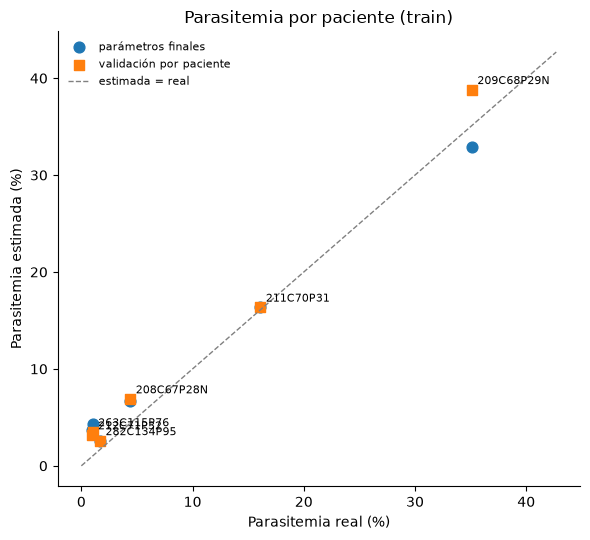

Guardados: results/c7_parasitemia_paciente.csv y results/c7_clasificacion_segmentadas.csv


In [9]:
print("Por imagen:")
print(parasitemia_imagen.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 5.5))
for col, marcador, nombre in [("estimada, parámetros finales (%)", "o", "parámetros finales"),
                              ("estimada, validación por paciente (%)", "s", "validación por paciente")]:
    ax.scatter(parasitemia_paciente["parasitemia real (%)"], parasitemia_paciente[col], marker=marcador, s=60, label=nombre)
lim = max(parasitemia_paciente.drop(columns="detectadas").max()) * 1.1
ax.plot([0, lim], [0, lim], color="gray", linestyle="--", linewidth=1, label="estimada = real")
for p, f in parasitemia_paciente.iterrows():
    ax.annotate(p.split("_")[0].replace("ThinF", ""), (f["parasitemia real (%)"], f["estimada, validación por paciente (%)"]),
                fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("Parasitemia real (%)")
ax.set_ylabel("Parasitemia estimada (%)")
ax.set_title("Parasitemia por paciente (train)")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

parasitemia_paciente.to_csv(CARPETA_RESULTADOS / "c7_parasitemia_paciente.csv")
resultados_clasificacion.to_csv(CARPETA_RESULTADOS / "c7_clasificacion_segmentadas.csv")
print("Guardados: results/c7_parasitemia_paciente.csv y results/c7_clasificacion_segmentadas.csv")

Ejemplo de la **máscara final** sobre una zona de una imagen de train: en **verde** los eritrocitos clasificados como parasitados (parámetros finales) y en **rojo** el contorno de los parasitados del GT.

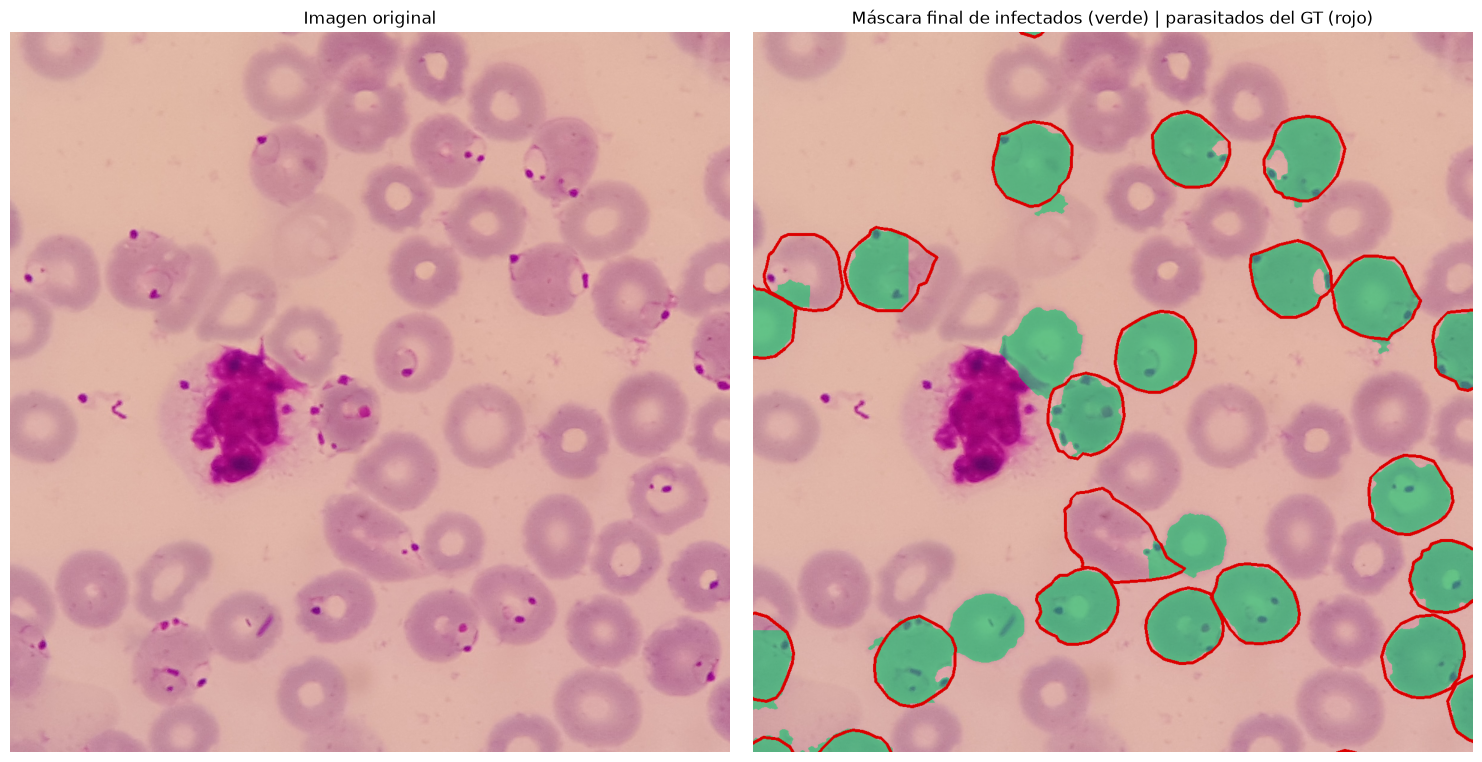

In [10]:
iid = "IMG_20150819_133447.jpg"
s = segmentaciones[iid]
img = cargar_imagen(s["patient_id"], iid)
d = celulas[celulas["image_id"] == iid]
mascara_final = mascara_infectados(s["etiquetas"], d.loc[d["parasitada_color"], "etiqueta"])
anot, _ = cargar_gt(s["patient_id"], iid)

pintada = img.copy()
pintada[mascara_final] = (0.45 * pintada[mascara_final] + 0.55 * np.array([0, 210, 110])).astype(np.uint8)
for a in anot:
    if a["label"] == LABEL_PARASITIZED:
        cv2.polylines(pintada, [np.round(a["polygon"]).astype(np.int32)], True, (220, 0, 0), 3)

cy, cx = np.array(np.nonzero(mascara_final)).mean(axis=1).astype(int)
mitad = 600
y0, x0 = max(cy - mitad, 0), max(cx - mitad, 0)
fig, ax = plt.subplots(1, 2, figsize=(15, 7.5))
ax[0].imshow(img[y0:y0 + 2 * mitad, x0:x0 + 2 * mitad])
ax[0].set_title("Imagen original")
ax[1].imshow(pintada[y0:y0 + 2 * mitad, x0:x0 + 2 * mitad])
ax[1].set_title("Máscara final de infectados (verde) | parasitados del GT (rojo)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

## 5. Conclusiones de C7

Todo es sobre las 12 imágenes de **train**. Test no se usó. Se verificó que cada célula segmentada corresponde a su etiqueta (`cell_id` y área de la máscara), así que el color se calculó sobre la máscara correcta.

1. **La segmentación del pipeline** detecta 2184 células en train: 1926 coinciden con eritrocitos sanos del GT, **199 con parasitados** y 59 no coinciden con ningún eritrocito del GT (`sin_pareja`).
2. **Las características de color siguen separando parasitadas y sanas en las células segmentadas.** El AUC por paciente cambia como mucho ±0.02 respecto de las células del GT. Las que más bajan son las de la mancha de C3 (`n_manchas`, `contraste_G_mancha`: de ≈0.96 a ≈0.94), probablemente porque el contorno de la segmentación es distinto del polígono del GT. `b_rel_p1`, `a_desvio` y `area_cromatica` se mantienen en ≈0.96-0.97.
3. **Segmentación y clasificación por separado.** De los **217 eritrocitos parasitados** del GT de train:
   - **18 se pierden en la segmentación** (no quedan emparejados con ninguna célula detectada);
   - de las 199 emparejadas, el clasificador con los **parámetros finales** detecta **178** (sensibilidad del clasificador **0.894**), lo que da una **detección total de 178/217 = 82.0 %**;
   - con la validación por paciente detecta 187 (sensibilidad del clasificador 0.940; detección total 86.2 %).
   Además, entre los 59 objetos `sin_pareja` (que no entran en las métricas de clasificación), 5-6 quedan marcados como parasitados: serían **falsos positivos adicionales** en una evaluación completa.
4. **Qué representa cada evaluación:**
   - **Parámetros finales** (sensibilidad 0.894, precisión 0.777, F1 0.832): es el **clasificador tal como está configurado** y el que usaría el pipeline, pero sobre los datos de desarrollo.
   - **Validación por paciente del criterio de color sobre segmentaciones fijas del Bloque A** (sensibilidad 0.940, especificidad 0.968, precisión 0.754, F1 0.837, exactitud balanceada media por paciente 0.952): estima cómo generaliza el **criterio de color** a un paciente nuevo, pero con parámetros de C3 que **cambian entre vueltas** y con la **segmentación fija** (que no se validó dentro de cada vuelta). **No** es el rendimiento del pipeline final.
   Sobre las células del GT (C5) el mismo criterio daba sensibilidad 0.986 y F1 0.872: con la segmentación automática el rendimiento baja, como era esperable, pero se mantiene.
5. **Los parámetros finales detectan menos que los de la validación por paciente** (0.894 contra 0.940). Muchas vueltas de la validación anidada de C3 eligieron sin erosión o con área mínima 25, mientras que los finales usan erosión 5 y área mínima 50. Una posible explicación: el contorno de la segmentación es distinto al del GT, y la erosión de 5 píxeles puede borrar parásitos pegados al borde de la célula segmentada. **No reajustamos nada** mirando este resultado. Si se quiere mejorar, habría que volver a elegir los parámetros de C3 sobre las células segmentadas, con validación por paciente.
6. **Parasitemia:** en los pacientes con muchas células infectadas la estimación es buena (211C70P31: real 16.1 %, estimada 16.4 %; 209C68P29N: real 35.1 %, estimada 32.9-38.8 % según los parámetros). En los pacientes con **parasitemia baja (≈1-2 %)** se **sobreestima 2 a 4 veces** (212C71P32: real 1.0 %, estimada 3.2-3.6 %; 263C115P76: real 1.0 %, estimada 3.5-4.3 %), porque 10-13 falsos positivos pesan mucho cuando hay solo 4-5 parasitadas. Esto muestra que **una buena sensibilidad no garantiza una buena estimación de la parasitemia**, y es el costo que se anticipó en C5 al priorizar la sensibilidad.
7. **Máscara final de eritrocitos infectados** (superposición global con los parasitados del GT, no identificación uno a uno): con los parámetros finales, Dice de **0.65-0.98** en las imágenes con más parasitadas o pocos falsos positivos (0.81-0.91 en los pacientes 209C68P29N y 211C70P31), y de **0.16-0.44** en las de parasitemia baja con falsos positivos, donde estos ocupan buena parte de la máscara.
8. **Limitaciones:**
   - los parámetros finales de C3 y los de la segmentación del Bloque A se eligieron con estos mismos pacientes de train;
   - la parasitemia real se calcula con todos los eritrocitos del GT, y la estimada con las células que detecta la segmentación (que descarta las del borde), así que no son exactamente la misma población;
   - la correspondencia con el GT exige IoU ≥ 0.5: las células muy mal segmentadas quedan como `sin_pareja` y no entran en las métricas de clasificación (sí en la parasitemia).
9. **Para la integración:** todo lo necesario ya está en `color_stain/`. `main.py` solo tendría que calcular `fondo = mediana_fondo(imagen_rgb, campo)` por imagen y llamar, para cada célula, a `caracteristicas_celula(crop, mask, fondo)` y `clasificar_color(atributos)`; después, `parasitemia(...)` y `mascara_infectados(etiquetas, ids)` por imagen. Este notebook muestra que esa cadena funciona sobre las células segmentadas.

**Archivos generados (en `color_stain/results/`):** `c7_clasificacion_segmentadas.csv` (métricas de clasificación) y `c7_parasitemia_paciente.csv` (parasitemia real y estimada por paciente).